# Chapter 17 — Employee Stock Options and Equity Compensation

Code behind the numbers in the chapter: the Black–Scholes values of a grant at
its contractual and expected terms, the Hull–White lattice with an exercise
multiple and an exit rate, dilution three ways, the exercise decision after tax,
vesting tranches and their recognition, repricing against a value-for-value
exchange, RSUs against options, the private-company exercise trap, and the
arithmetic of backdating.

| Section | What it reproduces |
|---|---|
| 1 | Black–Scholes at the contractual, simplified and expected terms (Example 17.1) |
| 2 | The employee-option lattice, checked against a closed form (Section 17.3) |
| 3 | Turnover against the exercise multiple (Example 17.1, Figure 17.2) |
| 4 | Warrant dilution, $N/(N+M)$ (Example 17.2) |
| 5 | The treasury stock method against economic dilution (Example 17.3) |
| 6 | Three things to do with a vested option (Example 17.4) |
| 7 | Vesting tranches on two bases, straight-line against graded (Example 17.5) |
| 8 | Repricing against a value-for-value exchange (Example 17.6) |
| 9 | RSUs against options as the stock falls (Example 17.7, Figure 17.3) |
| 10 | The exercise-and-hold trap (Example 17.8) |
| 11 | Backdating: the expected discount of a month's low (Example 17.9) |

Each cell prints the computed value beside the one the chapter prints, to the
decimals the chapter gives, so a figure that has drifted is visible rather than
merely absent. NumPy for the lattice and the grid, matplotlib for the figures;
everything else is the standard library. The whole notebook runs in well under
a minute.

In [1]:
from math import log, sqrt, exp, ceil, erfc

import numpy as np
import matplotlib.pyplot as plt


def show(label, got, printed, dp=4):
    """Print a computed value beside the one the chapter prints, compared at the chapter's decimals."""
    flag = "ok" if abs(got - printed) <= 0.5 * 10 ** -dp + 1e-12 else "DIFFERS"
    print("%-56s %16.6f   book %14s   %s" % (label, got, "%.*f" % (dp, printed), flag))


def N(x):
    """Standard normal distribution function, from the complementary error function."""
    return 0.5 * erfc(-x / sqrt(2.0))


def bsm(S, K, r, sigma, T, q=0.0):
    """Black-Scholes-Merton call value and delta, with a continuous yield q."""
    d1 = (log(S / K) + (r - q + 0.5 * sigma * sigma) * T) / (sigma * sqrt(T))
    d2 = d1 - sigma * sqrt(T)
    call = S * exp(-q * T) * N(d1) - K * exp(-r * T) * N(d2)
    return call, exp(-q * T) * N(d1)


# The chapter's running grant: S0 = K = 40, sigma = 30%, r = 4%, q = 1%, ten-year term.
R, Q, SIG = 0.04, 0.01, 0.30

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one. Series are distinguished by dash pattern as well
# as color, because the book prints in grayscale.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. Three Black–Scholes answers for one grant (Example 17.1)

The grant is at the money, $S_0 = K = 40$, with a ten-year term, a three-year
cliff, $\sigma = 30\%$, $r = 4\%$ and $q = 1\%$. Approach 1 puts the contractual
ten years into the formula. Approach 2 puts in an expected term instead: 6 or 4.5
years from the company's history, or, failing a usable history, the simplified
method of SABs 107 and 110, which takes the midpoint of vesting and the
contractual term, $(3 + 10)/2 = 6.5$ years. The lattice row of the table comes in
notebook section 2.

The spread across the four rows is the ratio of the largest to the smallest.
Notebook section 3 narrows it to the methods ASC 718 allows.

In [2]:
show("SAB 107/110 simplified term (3 + 10) / 2, years", (3 + 10) / 2, 6.5, 1)

EX_17_1 = (("Black-Scholes, 10-year contractual term", 10.0, 16.704, 41.8),
           ("Black-Scholes, 6.5-year simplified term", 6.5, 13.808, 34.5),
           ("Black-Scholes, 6-year expected term", 6.0, 13.295, 33.2),
           ("Black-Scholes, 4.5-year expected term", 4.5, 11.552, 28.9))
bs_term = {}
for label, term, printed, pct in EX_17_1:
    bs_term[term] = bsm(40.0, 40.0, R, SIG, term, Q)[0]
    show(label, bs_term[term], printed, 3)
    show("  percent of the grant price", 100 * bs_term[term] / 40, pct, 1)

bs10, bs45 = bs_term[10.0], bs_term[4.5]
show("spread, 16.704 / 11.552", bs10 / bs45, 1.45, 2)

SAB 107/110 simplified term (3 + 10) / 2, years                  6.500000   book            6.5   ok
Black-Scholes, 10-year contractual term                         16.704342   book         16.704   ok
  percent of the grant price                                    41.760855   book           41.8   ok
Black-Scholes, 6.5-year simplified term                         13.807714   book         13.808   ok
  percent of the grant price                                    34.519284   book           34.5   ok
Black-Scholes, 6-year expected term                             13.295038   book         13.295   ok
  percent of the grant price                                    33.237594   book           33.2   ok
Black-Scholes, 4.5-year expected term                           11.552346   book         11.552   ok
  percent of the grant price                                    28.880866   book           28.9   ok
spread, 16.704 / 11.552                                          1.445970   book           

## 2. The employee-option lattice (Section 17.3)

Approach 3 is the Hull–White lattice: the tree of Chapter 13 with optimal
exercise replaced by a behavioral rule. The employee exercises voluntarily once
the stock reaches $M$ times the strike; departures arrive at rate $\lambda$ a
year; a departure before vesting forfeits the option, and one after vesting
forces exercise of whatever is in the money.

The tree here is trinomial in $x = \ln(S/S_0)$, with the spacing chosen so that
a node falls *exactly* on the trigger $S = MK$. A Cox–Ross–Rubinstein tree lets
the trigger fall between nodes, so the employee in effect exercises a little
above $MK$ and every value comes out slightly high. With the trigger on a node
the tree converges at order $1/n$, so each value is Richardson-extrapolated from
$n$ and $2n$ steps: $V \approx 2V_{2n} - V_n$.

At each node the value is the discounted expectation over the three branches,
then:

* before vesting, the option survives a time step with probability $e^{-\lambda\,\Delta t}$ and is forfeited otherwise;
* after vesting, at or above the trigger it is exercised, $S - K$;
* after vesting, below the trigger, a departure (probability $1 - e^{-\lambda\,\Delta t}$) forces exercise at $\max(S-K, 0)$, and otherwise the option continues.

The optional `lam_pre` replaces the exit rate before vesting only; notebook section 7
uses it to value the option conditional on vesting.

**A closed-form check.** With no cliff and no departures the employee option
is an up-and-out call with barrier $H = MK$ plus a rebate of $H - K$ paid when
$H$ is first hit, and both pieces have exact prices (Chapter 34's barrier
formulas, and the Laplace transform of the first-passage time). The lattice
should agree to a few ten-thousandths.

In [3]:
def tree(S0, K, r, q, sigma, T, vest, M, lam, steps, lam_pre=None):
    """Hull-White employee option on a trinomial tree with a node on the trigger S = M K."""
    dt = T / steps
    b = log(M * K / S0)                       # distance to the trigger in log price
    if b <= 0:
        raise ValueError("the stock starts at or above the exercise trigger")
    n = max(1, ceil(b / (sigma * sqrt(3 * dt))))
    dx = b / n                                # so the trigger is exactly n steps up
    nu = r - q - 0.5 * sigma ** 2
    a = (sigma ** 2 * dt + nu ** 2 * dt ** 2) / dx ** 2
    pu, pd = 0.5 * (a + nu * dt / dx), 0.5 * (a - nu * dt / dx)
    pm = 1.0 - pu - pd
    disc = exp(-r * dt)
    p_exit = 1.0 - exp(-lam * dt)
    p_pre = p_exit if lam_pre is None else 1.0 - exp(-lam_pre * dt)
    # Grid: eight standard deviations below the start, and above the trigger only as far
    # as the pre-vesting period can carry the stock (after vesting it is exercised there).
    lo = -int(8 * sigma * sqrt(T) / dx) - 2
    hi = n + int(8 * sigma * sqrt(vest) / dx) + 2
    S = S0 * np.exp(np.arange(lo, hi + 1) * dx)
    trig = n - lo                             # index of the trigger node
    exercise = np.maximum(S - K, 0.0)
    V = exercise.copy()
    ivest = round(vest / dt)
    for i in range(steps - 1, -1, -1):
        up = np.append(V[1:], V[-1])
        down = np.insert(V[:-1], 0, V[0])
        cont = disc * (pu * up + pm * V + pd * down)
        if i >= ivest:
            V = p_exit * exercise + (1.0 - p_exit) * cont
            V[trig:] = exercise[trig:]
        else:
            V = (1.0 - p_pre) * cont
    return V[-lo]


def lattice(S0, K, r, q, sigma, T, vest, M, lam, steps=1500, lam_pre=None):
    """Richardson extrapolation from steps and 2 * steps."""
    v1 = tree(S0, K, r, q, sigma, T, vest, M, lam, steps, lam_pre)
    v2 = tree(S0, K, r, q, sigma, T, vest, M, lam, 2 * steps, lam_pre)
    return 2.0 * v2 - v1


def barrier_closed_form(S0, K, r, q, sigma, T, H):
    """Up-and-out call (K < H) plus a rebate of H - K paid when H is first hit."""
    sT = sigma * sqrt(T)
    lam = (r - q + 0.5 * sigma ** 2) / sigma ** 2
    y = log(H * H / (S0 * K)) / sT + lam * sT
    x1 = log(S0 / H) / sT + lam * sT
    y1 = log(H / S0) / sT + lam * sT
    up_in = (S0 * exp(-q * T) * N(x1) - K * exp(-r * T) * N(x1 - sT)
             - S0 * exp(-q * T) * (H / S0) ** (2 * lam) * (N(-y) - N(-y1))
             + K * exp(-r * T) * (H / S0) ** (2 * lam - 2) * (N(-y + sT) - N(-y1 + sT)))
    up_out = bsm(S0, K, r, sigma, T, q)[0] - up_in
    mu = r - q - 0.5 * sigma ** 2
    h = log(H / S0)
    eta = sqrt(mu * mu + 2 * r * sigma ** 2)
    hit = (exp(h * (mu - eta) / sigma ** 2) * N((-h + eta * T) / sT)
           + exp(h * (mu + eta) / sigma ** 2) * N((-h - eta * T) / sT))
    return up_out + (H - K) * hit


closed = barrier_closed_form(40.0, 40.0, R, Q, SIG, 10.0, 100.0)
for steps in (250, 500, 1000, 1500):
    v = lattice(40.0, 40.0, R, Q, SIG, 10.0, 0.0, 2.5, 0.0, steps)
    print("no cliff, no exits, M = 2.5: lattice from %4d/%4d steps %.6f   closed form %.6f   gap %+.1e"
          % (steps, 2 * steps, v, closed, v - closed))

no cliff, no exits, M = 2.5: lattice from  250/ 500 steps 15.960048   closed form 15.959563   gap +4.8e-04
no cliff, no exits, M = 2.5: lattice from  500/1000 steps 15.959325   closed form 15.959563   gap -2.4e-04
no cliff, no exits, M = 2.5: lattice from 1000/2000 steps 15.959457   closed form 15.959563   gap -1.1e-04
no cliff, no exits, M = 2.5: lattice from 1500/3000 steps 15.959549   closed form 15.959563   gap -1.4e-05


## 3. Turnover against the exercise multiple (Example 17.1, Figure 17.2)

The lattice row of Example 17.1, then its sensitivity table. Moving the exit rate
from 0% to 6% costs far more than moving the multiple from 2.0 to 3.0 gains, and
the gain from the multiple is smaller from 2.5 to 3.0 than from 2.0 to 2.5,
because a higher trigger matters only on the paths that reach it.

The last lines of the cell return to the spread of notebook section 1. ASC 718 rules out
the contractual-term row, which ignores early exercise; the methods it allows run
from the lattice's 15.56 conditional on vesting down to the 4.5-year 11.552, and on
one million options that vest the difference is the reported expense that turns
on the choice of method alone. Their ratio is printed beside the 1.45 of the full table.

In [4]:
base = lattice(40.0, 40.0, R, Q, SIG, 10.0, 3.0, 2.5, 0.03)
show("lattice, M = 2.5, exit 3% a year", base, 14.22, 2)
show("  percent of the grant price", 100 * base / 40, 35.5, 1)

cells = {(2.5, 0.03): base}
for M, lam, printed in ((2.0, 0.03, 13.54), (2.5, 0.0, 16.10), (2.5, 0.06, 12.59), (3.0, 0.03, 14.52)):
    cells[(M, lam)] = lattice(40.0, 40.0, R, Q, SIG, 10.0, 3.0, M, lam)
    show("lattice, M = %.1f, exit %d%%" % (M, round(100 * lam)), cells[(M, lam)], printed, 2)

print()
print("%-8s %10s %10s %10s" % ("", "exit 0%", "exit 3%", "exit 6%"))
for M in (2.0, 2.5, 3.0):
    row = ["%10.4f" % cells[(M, lam)] if (M, lam) in cells else "%10s" % "-" for lam in (0.0, 0.03, 0.06)]
    print("%-8s %s" % ("M = %.1f" % M, " ".join(row)))
print()
show("exit rate 0% to 6% costs", cells[(2.5, 0.0)] - cells[(2.5, 0.06)], 3.51, 2)
show("multiple 2.0 to 3.0 gains", cells[(3.0, 0.03)] - cells[(2.0, 0.03)], 0.98, 2)
print("gain from M = 2.0 to 2.5: %.4f;  from 2.5 to 3.0: %.4f"
      % (base - cells[(2.0, 0.03)], cells[(3.0, 0.03)] - base))
vested = lattice(40.0, 40.0, R, Q, SIG, 10.0, 3.0, 2.5, 0.03, lam_pre=0.0)
show("lattice conditional on vesting (standards' basis)", vested, 15.56, 2)
show("methods ASC 718 allows, 15.56 - 11.552 per 1m vested options, $m", vested - bs45, 4.0, 1)
print("spread without the contractual-term row: %.2f / %.3f = %.2f" % (vested, bs45, vested / bs45))

lattice, M = 2.5, exit 3% a year                                14.218463   book          14.22   ok
  percent of the grant price                                    35.546158   book           35.5   ok
lattice, M = 2.0, exit 3%                                       13.539588   book          13.54   ok
lattice, M = 2.5, exit 0%                                       16.104481   book          16.10   ok
lattice, M = 2.5, exit 6%                                       12.591345   book          12.59   ok
lattice, M = 3.0, exit 3%                                       14.520759   book          14.52   ok

            exit 0%    exit 3%    exit 6%
M = 2.0           -    13.5396          -
M = 2.5     16.1045    14.2185    12.5913
M = 3.0           -    14.5208          -

exit rate 0% to 6% costs                                         3.513136   book           3.51   ok
multiple 2.0 to 3.0 gains                                        0.981171   book           0.98   ok
gain from M = 2.0 to 2

lattice conditional on vesting (standards' basis)               15.557477   book          15.56   ok
methods ASC 718 allows, 15.56 - 11.552 per 1m vested options, $m         4.005130   book            4.0   ok
spread without the contractual-term row: 15.56 / 11.552 = 1.35


Figure 17.2 plots the lattice value against the assumed exit rate at $M = 2.5$,
with the contractual-term Black–Scholes value as a ceiling. The eight plotted
points are recomputed and compared at the 0.002 the figure's three decimals can
carry; the curve is close to linear in an input that no market quotes.

Figure 17.2 points within 0.002, of 8                            8.000000   book              8   ok


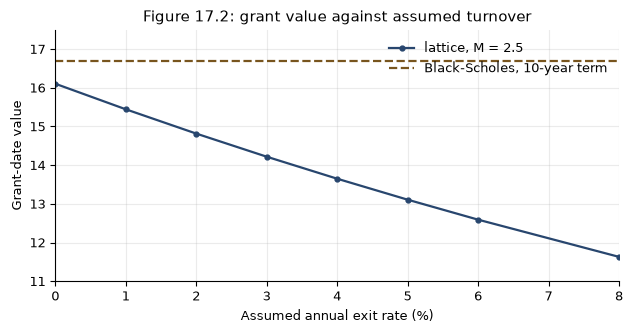

In [5]:
FIG_17_2 = ((0, 16.104), (1, 15.444), (2, 14.816), (3, 14.218), (4, 13.650),
            (5, 13.108), (6, 12.591), (8, 11.629))
exit_value = {}
for pct, printed in FIG_17_2:
    exit_value[pct] = base if pct == 3 else lattice(40.0, 40.0, R, Q, SIG, 10.0, 3.0, 2.5, pct / 100)
good = sum(abs(exit_value[pct] - printed) <= 0.002 for pct, printed in FIG_17_2)
show("Figure 17.2 points within 0.002, of 8", good, 8, 0)

rates = sorted(exit_value)
fig, ax = plt.subplots()
ax.plot(rates, [exit_value[p] for p in rates], color=BLUE, ls="-", lw=1.6, marker="o", ms=3.5,
        label="lattice, M = 2.5")
ax.axhline(bs10, color=AMBER, ls="--", lw=1.6, label="Black-Scholes, 10-year term")
ax.set_xlim(0, 8); ax.set_ylim(11, 17.5)
ax.set_xlabel("Assumed annual exit rate (%)"); ax.set_ylabel("Grant-date value")
ax.set_title("Figure 17.2: grant value against assumed turnover")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Warrant dilution (Example 17.2)

A warrant is $N/(N+M)$ of a call on $V/N$, the per-share value of the company
*excluding* the warrant proceeds (equation 17.1). With 10 million shares and
2 million five-year warrants struck at \$40, the factor is $10/12$, and the value
handed to the warrant holders is the fall in the share price if they are given
away. Here $M$ counts warrants, not the exercise multiple.

The Chinese edition states the total in units of \$10,000 (2,029 万美元); the
cell prints both forms.

In [6]:
c5 = bsm(40.0, 40.0, R, SIG, 5.0, Q)[0]
show("five-year call, S = K = 40", c5, 12.171, 3)
show("dilution factor 10 / 12", 10 / 12, 0.8333, 4)
warrant = 10 / 12 * c5
show("warrant", warrant, 10.143, 3)
show("discount to the call, percent", 100 * (1 - warrant / c5), 16.7, 1)
show("total for 2m warrants, $m", 2 * warrant, 20.3, 1)
show("total, in $10,000 (Chinese edition)", 200 * warrant, 2029, 0)
show("price fall on 10m shares, $", 2 * warrant / 10, 2.03, 2)
show("price afterward, $", 40 - 2 * warrant / 10, 37.97, 2)

five-year call, S = K = 40                                      12.171223   book         12.171   ok
dilution factor 10 / 12                                          0.833333   book         0.8333   ok
warrant                                                         10.142686   book         10.143   ok
discount to the call, percent                                   16.666667   book           16.7   ok
total for 2m warrants, $m                                       20.285371   book           20.3   ok
total, in $10,000 (Chinese edition)                           2028.537126   book           2029   ok
price fall on 10m shares, $                                      2.028537   book           2.03   ok
price afterward, $                                              37.971463   book          37.97   ok


## 5. The treasury stock method against economic dilution (Example 17.3)

Ten million shares, \$50 million of net income, 1 million options struck at \$30,
an average price of \$50, and \$6 million of grant-date cost that remains
unrecognized on average over the period.
The treasury stock method treats the strike and the unrecognized cost as proceeds
used to buy back shares at the average price, and counts the rest as incremental
shares. It values each option at its intrinsic value less unrecognized cost, which
the cell confirms: the 0.28 million incremental shares times \$50 equal
$1\text{m} \times (50 - 30) - 6\text{m}$.

The economic measure values the grant instead: six years at $S = 50$, $K = 30$
gives \$25.68 an option, about 5% of a \$500 million company, roughly twice the
reported 2.8%. The first line checks the "about \$10" at grant, with the stock
at \$30.

In [7]:
c_grant = bsm(30.0, 30.0, R, SIG, 6.0, Q)[0]
show("grant-date value at S = K = 30, about $10", c_grant, 10, 0)
show("basic EPS, $", 50 / 10, 5.00, 2)
show("proceeds incl. unrecognized cost, $m", 1 * 30 + 6, 36, 0)
show("shares bought back, m", 36 / 50, 0.72, 2)
show("incremental shares, m", 1.00 - 36 / 50, 0.28, 2)
show("diluted EPS, $", 50 / (10 + 1.00 - 36 / 50), 4.864, 3)
show("reported dilution, percent", 100 * 0.28 / 10, 2.8, 1)
show("fall in EPS, percent", 100 * (1 - 10 / 10.28), 2.7, 1)
print("treasury stock check: 0.28m x $50 = $%.1fm;  intrinsic less unrecognized = $%.1fm"
      % (0.28 * 50, 1 * (50 - 30) - 6))
print()
c_now = bsm(50.0, 30.0, R, SIG, 6.0, Q)[0]
show("six-year option, S = 50, K = 30", c_now, 25.68, 2)
show("grant value, $m", 1 * c_now, 25.7, 1)
show("economic dilution, percent of $500m", 100 * c_now / 500, 5.1, 1)

grant-date value at S = K = 30, about $10                        9.971278   book             10   ok
basic EPS, $                                                     5.000000   book           5.00   ok
proceeds incl. unrecognized cost, $m                            36.000000   book             36   ok
shares bought back, m                                            0.720000   book           0.72   ok
incremental shares, m                                            0.280000   book           0.28   ok
diluted EPS, $                                                   4.863813   book          4.864   ok
reported dilution, percent                                       2.800000   book            2.8   ok
fall in EPS, percent                                             2.723735   book            2.7   ok
treasury stock check: 0.28m x $50 = $14.0m;  intrinsic less unrecognized = $14.0m

six-year option, S = 50, K = 30                                 25.680303   book          25.68   ok
grant va

## 6. Three things to do with a vested option (Example 17.4)

10,000 vested non-qualified options (NSOs) struck at \$20, the stock at \$50,
four years left, $\sigma = 35\%$, $r = 4\%$, no dividend, a 40% marginal tax rate.
The cell prices the corresponding traded call, then the three rows of the table:
hold, exercise and sell, exercise and hold.

The comparison that matters is between the first two rows, after tax on both
sides, since the options also owe the tax when eventually exercised. The
difference is 60% of the time value, which is the price of diversifying.

Then the two sharpening remarks: the time value at a stock price of \$120 is
barely changed, and it never falls below the interest on the deferred strike,
$K(1 - e^{-rT})$; what does fall is the time value as a fraction of the
intrinsic value.

In [8]:
c4 = bsm(50.0, 20.0, R, 0.35, 4.0)[0]
show("call, S = 50, K = 20, T = 4, sigma = 35%", c4, 33.483, 3)
show("time value", c4 - 30, 3.483, 3)
show("time value, percent of intrinsic", 100 * (c4 - 30) / 30, 11.6, 1)
show("time value on 10,000 options, $", 10000 * (c4 - 30), 34826, 0)
print()
show("hold: model value before tax, $", 10000 * c4, 334826, 0)
show("exercise and sell: cash after tax, $", 0.6 * 10000 * (50 - 20), 180000, 0)
show("exercise and hold: strike plus tax, $", 10000 * 20 + 0.4 * 10000 * (50 - 20), 320000, 0)
hold_after_tax = 0.6 * 10000 * c4
show("hold, after the tax due on eventual exercise, $", hold_after_tax, 200896, 0)
show("cost of diversifying, $ to the nearest hundred", round(hold_after_tax - 180000, -2), 20900, 0)
show("  = 0.6 x time value on the position, nearest $100", round(0.6 * 10000 * (c4 - 30), -2), 20900, 0)
print()
c120 = bsm(120.0, 20.0, R, 0.35, 4.0)[0]
show("time value at S = 120", c120 - 100, 2.98, 2)
show("floor K(1 - e^{-rT})", 20 * (1 - exp(-R * 4.0)), 2.96, 2)
show("time value at 120, percent of intrinsic", 100 * (c120 - 100) / 100, 3.0, 1)

call, S = 50, K = 20, T = 4, sigma = 35%                        33.482594   book         33.483   ok
time value                                                       3.482594   book          3.483   ok
time value, percent of intrinsic                                11.608647   book           11.6   ok
time value on 10,000 options, $                              34825.940040   book          34826   ok

hold: model value before tax, $                             334825.940040   book         334826   ok
exercise and sell: cash after tax, $                        180000.000000   book         180000   ok
exercise and hold: strike plus tax, $                       320000.000000   book         320000   ok
hold, after the tax due on eventual exercise, $             200895.564024   book         200896   ok
cost of diversifying, $ to the nearest hundred               20900.000000   book          20900   ok
  = 0.6 x time value on the position, nearest $100           20900.000000   book          

## 7. Vesting tranches on two bases (Example 17.5)

A grant of 100,000 options vesting 25% a year is four options with cliffs at one
to four years. The lattice of notebook section 2 values each with its own cliff, and those
values are the *expected cost per option granted*, including the chance of
leaving before vesting, so they fall as the cliff lengthens.

The standards measure fair value *conditional on vesting* and put pre-vesting
departures into the number of awards. Pre-vesting departure is independent of
the stock, so dividing by the probability of staying to the cliff,
$e^{-0.03c}$, gives the conditional value; the cell checks one tranche against a
tree run with no exits before vesting (`lam_pre=0`). On this basis the values
rise with the cliff.

A third column runs the same four trees with no departures at all, before or
after vesting, so that only the voluntary exercise at the multiple shortens the
option's life. A later cliff delays the earliest date at which the employee can
exercise at $M = 2.5$, and these values also rise with the cliff, from about
15.96 to 16.24. The chapter does not print this column; it is here to separate
the two effects at work in the conditional values.

In [9]:
tranche, conditional, no_exits = {}, {}, {}
for cliff, printed, printed_cond in ((1, 14.52, 14.96), (2, 14.37, 15.26), (3, 14.22, 15.56), (4, 14.05, 15.85)):
    tranche[cliff] = base if cliff == 3 else lattice(40.0, 40.0, R, Q, SIG, 10.0, cliff, 2.5, 0.03)
    conditional[cliff] = tranche[cliff] * exp(0.03 * cliff)
    no_exits[cliff] = cells[(2.5, 0.0)] if cliff == 3 else lattice(40.0, 40.0, R, Q, SIG, 10.0, cliff, 2.5, 0.0)
    show("%d-year cliff, expected cost per option granted" % cliff, tranche[cliff], printed, 2)
    show("%d-year cliff, conditional on vesting" % cliff, conditional[cliff], printed_cond, 2)
show("3-year cliff, from a tree with no exits before vesting",
     lattice(40.0, 40.0, R, Q, SIG, 10.0, 3.0, 2.5, 0.03, lam_pre=0.0), 15.56, 2)
show("first to fourth tranche, percent lower", 100 * (1 - tranche[4] / tranche[1]), 3.2, 1)

print()
print("%-6s %16s %16s %16s" % ("cliff", "expected cost", "cond. on vest", "no departures"))
for cliff in (1, 2, 3, 4):
    print("%-6d %16.4f %16.4f %16.4f" % (cliff, tranche[cliff], conditional[cliff], no_exits[cliff]))

1-year cliff, expected cost per option granted                  14.519203   book          14.52   ok
1-year cliff, conditional on vesting                            14.961378   book          14.96   ok


2-year cliff, expected cost per option granted                  14.369532   book          14.37   ok
2-year cliff, conditional on vesting                            15.258095   book          15.26   ok
3-year cliff, expected cost per option granted                  14.218463   book          14.22   ok
3-year cliff, conditional on vesting                            15.557477   book          15.56   ok


4-year cliff, expected cost per option granted                  14.053806   book          14.05   ok
4-year cliff, conditional on vesting                            15.845622   book          15.85   ok


3-year cliff, from a tree with no exits before vesting          15.557477   book          15.56   ok
first to fourth tranche, percent lower                           3.205388   book            3.2   ok

cliff     expected cost    cond. on vest    no departures
1               14.5192          14.9614          15.9614
2               14.3695          15.2581          16.0034
3               14.2185          15.5575          16.1045
4               14.0538          15.8456          16.2358


The dollar costs are 25,000 times the two-decimal values the table prints.
Straight-line recognition spreads the total evenly. Graded recognition treats each
tranche as its own award expensed over its own vesting period, so year 1 carries
all of tranche 1, half of tranche 2, a third of tranche 3 and a quarter of tranche
4. Each graded amount is an exact half-dollar, and the chapter rounds half to
even, as Python's `round` does, so the four years sum to the printed total.

In [10]:
TABLE_17_5 = ((14.52, 363000), (14.37, 359250), (14.22, 355500), (14.05, 351250))
cost = []
for k, (value, printed) in enumerate(TABLE_17_5):
    cost.append(25000 * value)
    show("tranche %d cost, 25,000 x %.2f, $" % (k + 1, value), cost[-1], printed, 0)
total = sum(cost)
show("total, $", total, 1429000, 0)
show("straight-line, each year, $", total / 4, 357250, 0)
graded = [round(sum(cost[k] / (k + 1) for k in range(year, 4))) for year in range(4)]
for year, printed in enumerate((748938, 385938, 206312, 87812)):
    show("graded, year %d, $" % (year + 1), graded[year], printed, 0)
show("graded years sum to, $", sum(graded), 1429000, 0)
show("graded first year, percent of total", 100 * graded[0] / total, 52, 0)

print()
print("%-14s %12s %12s %12s %12s" % ("", "Year 1", "Year 2", "Year 3", "Year 4"))
print("%-14s %s" % ("Straight-line", " ".join("%12s" % format(round(total / 4), ",") for _ in range(4))))
print("%-14s %s" % ("Graded", " ".join("%12s" % format(g, ",") for g in graded)))

tranche 1 cost, 25,000 x 14.52, $                           363000.000000   book         363000   ok
tranche 2 cost, 25,000 x 14.37, $                           359250.000000   book         359250   ok
tranche 3 cost, 25,000 x 14.22, $                           355500.000000   book         355500   ok
tranche 4 cost, 25,000 x 14.05, $                           351250.000000   book         351250   ok
total, $                                                   1429000.000000   book        1429000   ok
straight-line, each year, $                                 357250.000000   book         357250   ok
graded, year 1, $                                           748938.000000   book         748938   ok
graded, year 2, $                                           385938.000000   book         385938   ok
graded, year 3, $                                           206312.000000   book         206312   ok
graded, year 4, $                                            87812.000000   book          8

## 8. Repricing against a value-for-value exchange (Example 17.6)

500,000 options struck at \$80, the stock at \$30, six years left, $\sigma = 45\%$,
$r = 4\%$, no dividend. Repricing to \$30 adds the difference in fair value per
option. A value-for-value exchange hands over new at-the-money options in the
ratio of the two values, so nothing is added and nothing is expensed.

The incentive is the delta of the grant, the number of shares of exposure the
employee holds. A deeply out-of-the-money option has a surprisingly high delta,
so the exchange that costs nothing to report leaves the employee with less
exposure than before. The chapter's \$8.0583 is the difference of the two
four-decimal prices; the unrounded difference is 8.05824, and the cell prints
both. The chapter's dollar and share columns are computed from
the unrounded values and option count; the cell does the same.

The Chinese edition states the incremental expense as 402.9 万美元; the cell
prints that form too.

In [11]:
old, delta_old = bsm(30.0, 80.0, R, 0.45, 6.0)
new, delta_new = bsm(30.0, 30.0, R, 0.45, 6.0)
show("underwater option, K = 80", old, 6.5944, 4)
show("new at-the-money option, K = 30", new, 14.6527, 4)
show("repricing adds per option, unrounded", new - old, 8.058, 3)
show("  from the printed values, 14.6527 - 6.5944", 14.6527 - 6.5944, 8.0583, 4)
ratio = old / new
show("exchange ratio, new per old", ratio, 0.45005, 5)
show("options after the exchange", round(500000 * ratio), 225025, 0)
show("fair value before, $", 500000 * old, 3297207, 0)
show("fair value after repricing, $", 500000 * new, 7326327, 0)
show("incremental expense of repricing, $", 500000 * (new - old), 4029120, 0)
show("  in $ millions", 500000 * (new - old) / 1e6, 4.0, 1)
show("  in $10,000 (Chinese edition)", 500000 * (new - old) / 1e4, 402.9, 1)
print()
show("delta, underwater", delta_old, 0.452, 3)
show("delta, at the money", delta_new, 0.779, 3)
show("shares of exposure, underwater", 500000 * delta_old, 225931, 0)
show("shares of exposure, repriced", 500000 * delta_new, 389507, 0)
show("shares of exposure, exchanged", 500000 * ratio * delta_new, 175297, 0)
show("exchange against underwater, percent less", 100 * (1 - ratio * delta_new / delta_old), 22, 0)
show("repricing multiplies value by", new / old, 2.2, 1)
show("repricing multiplies exposure by", delta_new / delta_old, 1.7, 1)

underwater option, K = 80                                        6.594414   book         6.5944   ok
new at-the-money option, K = 30                                 14.652654   book        14.6527   ok
repricing adds per option, unrounded                             8.058240   book          8.058   ok
  from the printed values, 14.6527 - 6.5944                      8.058300   book         8.0583   ok
exchange ratio, new per old                                      0.450049   book        0.45005   ok
options after the exchange                                  225025.000000   book         225025   ok
fair value before, $                                       3297207.064608   book        3297207   ok
fair value after repricing, $                              7326327.136706   book        7326327   ok
incremental expense of repricing, $                        4029120.072099   book        4029120   ok
  in $ millions                                                  4.029120   book           

## 9. RSUs against options as the stock falls (Example 17.7, Figure 17.3)

The two must be valued on one basis. The option's 14.22 is an expected cost per
option granted, carrying the chance of leaving before the cliff, so the RSU
carries it too: a unit without dividend equivalents is a prepaid forward that is
forfeited on departure before vesting, worth $Se^{-(q+\lambda)T}$ with $T = 3$.
Conditional on vesting, both values rise by the same $e^{0.09}$, so the ratio is
unchanged.

Then the drawdown table: the stock falls at once to \$30 and to \$20, with the
strike and the vesting unchanged. The RSU loses exactly the fraction the stock
loses; the option loses more.

In [12]:
RSU_FACTOR = exp(-(Q + 0.03) * 3.0)
rsu = 40.0 * RSU_FACTOR
show("RSU at 40, 40 e^{-(0.01 + 0.03) x 3}", rsu, 35.48, 2)
show("options per RSU", rsu / base, 2.50, 2)
show("options per RSU, conditional on vesting", (rsu * exp(0.09)) / (base * exp(0.09)), 2.50, 2)

option_at = {40: base}
for S, rsu_printed, rsu_chg, opt_printed, opt_chg in ((30, 26.61, -25, 8.41, -41), (20, 17.74, -50, 3.68, -74)):
    option_at[S] = lattice(float(S), 40.0, R, Q, SIG, 10.0, 3.0, 2.5, 0.03)
    show("RSU at %d" % S, S * RSU_FACTOR, rsu_printed, 2)
    show("  change, percent", 100 * (S * RSU_FACTOR / rsu - 1), rsu_chg, 0)
    show("option at %d" % S, option_at[S], opt_printed, 2)
    show("  change, percent", 100 * (option_at[S] / base - 1), opt_chg, 0)

print()
print("%-12s %10s %8s %12s %8s" % ("Stock price", "RSU", "change", "Option", "change"))
for S in (40, 30, 20):
    print("%-12d %10.2f %7.0f%% %12.2f %7.0f%%" % (S, S * RSU_FACTOR, 100 * (S / 40 - 1),
                                                   option_at[S], 100 * (option_at[S] / base - 1)))

RSU at 40, 40 e^{-(0.01 + 0.03) x 3}                            35.476817   book          35.48   ok
options per RSU                                                  2.495123   book           2.50   ok
options per RSU, conditional on vesting                          2.495123   book           2.50   ok
RSU at 30                                                       26.607613   book          26.61   ok
  change, percent                                              -25.000000   book            -25   ok
option at 30                                                     8.409724   book           8.41   ok
  change, percent                                              -40.853497   book            -41   ok
RSU at 20                                                       17.738409   book          17.74   ok
  change, percent                                              -50.000000   book            -50   ok
option at 20                                                     3.683620   book           

Figure 17.3 draws the two against the share price. The RSU is a straight line
through the origin; the option curve bends away from it and flattens toward
zero, so the same fall in the stock takes proportionally more of the option. The
option's eleven plotted points are lattice values, compared within 0.002, and the
RSU's six are exact.

Figure 17.3 option points within 0.002, of 11                   11.000000   book             11   ok
Figure 17.3 RSU points that reproduce, of 6                      6.000000   book              6   ok


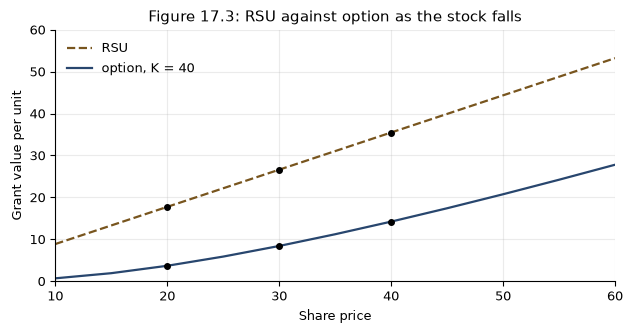

In [13]:
FIG_17_3_OPTION = ((10, 0.689), (15, 1.918), (20, 3.684), (25, 5.878), (30, 8.409), (35, 11.206),
                   (40, 14.218), (45, 17.408), (50, 20.746), (55, 24.212), (60, 27.788))
FIG_17_3_RSU = ((10, 8.869), (20, 17.738), (30, 26.608), (40, 35.477), (50, 44.346), (60, 53.215))
for S, _ in FIG_17_3_OPTION:
    if S not in option_at:
        option_at[S] = lattice(float(S), 40.0, R, Q, SIG, 10.0, 3.0, 2.5, 0.03)
good = sum(abs(option_at[S] - v) <= 0.002 for S, v in FIG_17_3_OPTION)
show("Figure 17.3 option points within 0.002, of 11", good, 11, 0)
good = sum(abs(S * RSU_FACTOR - v) <= 0.5e-3 for S, v in FIG_17_3_RSU)
show("Figure 17.3 RSU points that reproduce, of 6", good, 6, 0)

prices = sorted(option_at)
fig, ax = plt.subplots()
ax.plot([10, 60], [10 * RSU_FACTOR, 60 * RSU_FACTOR], color=AMBER, ls="--", lw=1.6, label="RSU")
ax.plot(prices, [option_at[S] for S in prices], color=BLUE, ls="-", lw=1.6, label="option, K = 40")
ax.plot([20, 30, 40, 20, 30, 40], [option_at[20], option_at[30], option_at[40],
                                    20 * RSU_FACTOR, 30 * RSU_FACTOR, 40 * RSU_FACTOR],
        ls="none", marker="o", ms=4, color="black")
ax.set_xlim(10, 60); ax.set_ylim(0, 60)
ax.set_xlabel("Share price"); ax.set_ylabel("Grant value per unit")
ax.set_title("Figure 17.3: RSU against option as the stock falls")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

## 10. The exercise-and-hold trap (Example 17.8)

An engineer leaving a private company holds 100,000 vested incentive stock
options (ISOs) struck at \$0.50, with a 409A value of \$8.00. Exercising costs
the strike in cash, and the alternative minimum tax (AMT) counts the spread as
income, so a tax bill arrives on shares that cannot be sold.

In [14]:
cash_strike = 100000 * 0.50
amt_income = (8.00 - 0.50) * 100000
amt = 0.28 * amt_income
show("cash to exercise, $", cash_strike, 50000, 0)
show("AMT income, $", amt_income, 750000, 0)
show("AMT at 28%, $", amt, 210000, 0)
show("total cash required, $", cash_strike + amt, 260000, 0)

cash to exercise, $                                          50000.000000   book          50000   ok
AMT income, $                                               750000.000000   book         750000   ok
AMT at 28%, $                                               210000.000000   book         210000   ok
total cash required, $                                      260000.000000   book         260000   ok


## 11. Backdating: the expected discount of a month's low (Example 17.9)

Over a 21-trading-day month (21 closing prices, days 0 to 20) of a stock with
45% volatility, $r = 4\%$ and $q = 1\%$, how far below the price on a randomly
chosen day does the month's minimum lie, in expectation?

**Computed on a grid.** The minimum of a random walk has the distribution of a
reflected (Lindley) recursion: write $X_k$ for the daily log increment, and
$W_k = \max(0, W_{k-1} - X_k)$, $W_0 = 0$, has the law of $-\min_{j \le k}
\ln(S_j/S_0)$. The cell propagates the distribution of $W$ on a grid of spacing
0.0005 by convolving it with the Gaussian increment, twenty times, and reads off
$E[e^{-W_{20}}]$. The expected price on a random day is the average of
$e^{(r-q)k/252}$ over the 21 days. Nothing here is simulated.

In [15]:
def expected_min_discount(sigma, r, q, prices=21, h=0.0005):
    """1 - E[minimum of the month] / E[price on a randomly chosen day], on a grid."""
    days, dt = prices - 1, 1 / 252
    mu, sd = (r - q - 0.5 * sigma ** 2) * dt, sigma * sqrt(dt)
    width = int(6 * sd / h) + 1
    edges = (np.arange(-width, width + 2) - 0.5) * h
    # The step of W is Y = -X, normal with mean -mu; kernel[k] is P(Y in cell k - width).
    kernel = np.diff([N((e + mu) / sd) for e in edges])
    size = int((sqrt(days) * 6 * sd + days * abs(mu)) / h) + width + 2
    dist = np.zeros(size)
    dist[0] = 1.0
    for _ in range(days):
        full = np.convolve(dist, kernel)           # index i + k, i.e. cell i + (k - width) after the shift
        new = full[width:width + size].copy()
        new[0] += full[:width].sum()               # the reflection: everything below zero lands on zero
        dist = new
    e_min = (dist * np.exp(-h * np.arange(size))).sum()
    e_day = np.mean([exp((r - q) * k * dt) for k in range(days + 1)])
    return 1.0 - e_min / e_day


discount = expected_min_discount(0.45, R, Q)
show("expected minimum below a random day, percent", 100 * discount, 8.3, 1)

expected minimum below a random day, percent                     8.334787   book            8.3   ok


**Checked by simulation.** The same quantity by Monte Carlo, with a fixed seed
so a rerun prints the same digits. This is a simulation, and its last digit
carries the standard error printed beside it; the grid above is the computation
the chapter's figure rests on.

In [16]:
rng = np.random.default_rng(17)
paths, dt = 400000, 1 / 252
steps = rng.normal((R - Q - 0.5 * 0.45 ** 2) * dt, 0.45 * sqrt(dt), size=(paths, 20))
log_path = np.concatenate([np.zeros((paths, 1)), np.cumsum(steps, axis=1)], axis=1)
month_min = np.exp(log_path.min(axis=1))
e_day = np.mean([exp((R - Q) * k * dt) for k in range(21)])
mc = 1 - month_min.mean() / e_day
mc_se = month_min.std(ddof=1) / sqrt(paths) / e_day
print("SIMULATED, seed 17, %d paths: discount %.3f%% (standard error %.3f%%); grid %.3f%%"
      % (paths, 100 * mc, 100 * mc_se, 100 * discount))

SIMULATED, seed 17, 400000 paths: discount 8.323% (standard error 0.011%); grid 8.335%


**What the discount buys.** The honest strike is the month's typical \$40; the
backdated one is 8.3% lower, set in cents. The ten-year option's value rises only
a little, because at 45% volatility it is already worth more than half the stock.
The intrinsic value is what mattered under APB 25: the backdated option is in the
money from the start, and that amount on 500,000 options is the expense reported
as zero.

In [17]:
K_back = round(40.0 * (1 - discount), 2)          # a strike is set in cents
show("backdated strike, $", K_back, 36.67, 2)
show("in the money at grant, $", 40.0 - K_back, 3.33, 2)
v_honest = bsm(40.0, 40.0, R, 0.45, 10.0, Q)[0]
v_back = bsm(40.0, K_back, R, 0.45, 10.0, Q)[0]
show("ten-year option at K = 40", v_honest, 21.478, 3)
show("ten-year option at the backdated strike", v_back, 22.190, 3)
show("rise, percent", 100 * (v_back / v_honest - 1), 3.3, 1)
show("rise across 500,000 options, $ thousands", 500 * (v_back - v_honest), 356, 0)
show("value as percent of the stock", 100 * v_honest / 40, 54, 0)
show("concealed expense, 3.33 x 500,000, $m", (40.0 - K_back) * 500000 / 1e6, 1.67, 2)

backdated strike, $                                             36.670000   book          36.67   ok
in the money at grant, $                                         3.330000   book           3.33   ok
ten-year option at K = 40                                       21.478407   book         21.478   ok
ten-year option at the backdated strike                         22.190447   book         22.190   ok
rise, percent                                                    3.315146   book            3.3   ok
rise across 500,000 options, $ thousands                       356.020259   book            356   ok
value as percent of the stock                                   53.696016   book             54   ok
concealed expense, 3.33 x 500,000, $m                            1.665000   book           1.67   ok
